# 02. Modelling: Bank Account Fraud
Pipeline → model müqayisəsi → tuning → feature selection → calibration → threshold.

## 1. Setup

In [34]:
import inspect, json, re, time, warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.frozen import FrozenEstimator
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, precision_recall_curve, roc_curve
from sklearn.model_selection import ParameterGrid, ParameterSampler, train_test_split
from sklearn.pipeline import Pipeline

from src.config import *
from src.evaluation import *
from src.features import BAFCleaner, FeatureEngineer, build_pipeline

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
Path("models").mkdir(exist_ok=True)

## 2. Data Loading

In [35]:
df = pd.read_csv(DATA_PATH)
print(df.shape, f"| fraud rate: {df[TARGET].mean():.3%}")

(1000000, 32) | fraud rate: 1.103%


## 3. Preprocessing
### 3.1 Missing kodları və drop qərarı
Hamısı pipeline-dadır (`BAFCleaner`). Burada yalnız drop qərarını veririk.

In [36]:
# Sabit sütunlar məlumat vermir; month isə split açarıdır (feature kimi istifadə olunsa gələcəyə uyğunlaşa bilməz)
const_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
DROP_COLS = const_cols + [TIME_COL]
print("Drop:", DROP_COLS)
print(inspect.getsource(BAFCleaner.transform))

Drop: ['device_fraud_count', 'month']
    def transform(self, X):
        """-1/mənfi kodları NaN edir, *_missing indikatorlarını əlavə edir, drop_cols-u silir."""
        X = X.copy()
        for col in MISSING_MINUS1:
            if col in X:
                mask = X[col] == -1
                X[f"{col}_missing"] = mask.astype("int8")  # missing-in özü siqnal ola bilər
                X[col] = X[col].mask(mask)
        for col in NEGATIVE_MISSING:
            if col in X:
                mask = X[col] < 0
                X[f"{col}_missing"] = mask.astype("int8")
                X[col] = X[col].mask(mask)
        drop = [c for c in (self.drop_cols or []) if c in X]
        return X.drop(columns=drop)



### 3.2 Train / Validation / Test split (zamana görə)
Train: ay 0-4 → Valid: ay 5 → Test: ay 6-7. Valid: tuning, calibration, threshold. Test: yalnız final yoxlama.

In [37]:
def time_split(df: pd.DataFrame):
    """month sütununa görə train/valid/test (X, y) cütlərini qaytarır."""
    parts = {}
    for name, months in [("train", TRAIN_MONTHS), ("valid", VALID_MONTHS), ("test", TEST_MONTHS)]:
        part = df[df[TIME_COL].isin(months)]
        parts[name] = (part.drop(columns=[TARGET]), part[TARGET])
    return parts

splits = time_split(df)
X_tr, y_tr = splits["train"]; X_va, y_va = splits["valid"]; X_te, y_te = splits["test"]
pd.DataFrame({k: {"rows": len(v[0]), "fraud_rate": v[1].mean()} for k, v in splits.items()}).T

,rows,fraud_rate
train,675666.0,0.009975
valid,119323.0,0.011825
test,205011.0,0.014038


In [38]:
# Train skorunu tez hesablamaq üçün train-in 200k-lıq təsadüfi alt-çoxluğu (yalnız qiymətləndirmə üçün)
tr_eval = X_tr.sample(min(200_000, len(X_tr)), random_state=RANDOM_STATE)
eval_sets = {"train": (tr_eval, y_tr.loc[tr_eval.index]), "valid": (X_va, y_va), "test": (X_te, y_te)}

### 3.3 Imputation, scaling, encoding
Bu addımlar pipeline-ın `prep` hissəsindədir (bölmə 5) və yalnız train-də fit olunur (leakage yoxdur): rəqəmsal = median imputation + StandardScaler, kateqorik = most_frequent + OneHot.

## 4. Feature Engineering

In [39]:
print(inspect.getsource(FeatureEngineer.transform))

    def transform(self, X):
        """Domen əsaslı yeni feature-ləri əlavə edir (velocity, nisbətlər, interaksiyalar)."""
        X = X.copy()

        # 1) Velocity: qısa müddətli aktivlik uzunmüddətliyə nisbətən sıçrayıbmı
        X["velocity_ratio_6h_24h"] = X["velocity_6h"] / (X["velocity_24h"] + EPS)
        X["velocity_ratio_24h_4w"] = X["velocity_24h"] / (X["velocity_4w"] + EPS)
        X["velocity_accel"] = X["velocity_6h"] - X["velocity_4w"]

        # 2) Maliyyə nisbətləri: tələb olunan limit gəlirə / risk skoruna görə
        X["credit_limit_to_income"] = X["proposed_credit_limit"] / (X["income"] + 0.01)
        X["credit_risk_per_limit"] = X["credit_risk_score"] / (X["proposed_credit_limit"] + EPS)
        X["balcon_to_limit"] = X["intended_balcon_amount"] / (X["proposed_credit_limit"] + EPS)

        # 3) Yaşayış stabilliyi (customer_age onluqlarla verilib, ay = age*12)
        X["addr_months_total"] = self._nansum(
            X, ["current_address_months_count", "prev_ad

In [40]:
fe_only = Pipeline([("clean", BAFCleaner(DROP_COLS)), ("fe", FeatureEngineer())])
Xtr_fe = fe_only.fit_transform(X_tr)
new_feats = [c for c in Xtr_fe.columns if c not in X_tr.columns]
print(f"{len(new_feats)} yeni feature:", new_feats)

22 yeni feature: ['prev_address_months_count_missing', 'current_address_months_count_missing', 'bank_months_count_missing', 'session_length_in_minutes_missing', 'device_distinct_emails_8w_missing', 'intended_balcon_amount_missing', 'velocity_ratio_6h_24h', 'velocity_ratio_24h_4w', 'velocity_accel', 'credit_limit_to_income', 'credit_risk_per_limit', 'balcon_to_limit', 'addr_months_total', 'current_addr_share_of_life', 'distinct_emails_total', 'phone_valid_count', 'email_risk', 'session_log', 'short_session', 'zip_count_log', 'branch_count_log', 'teleapp_foreign']


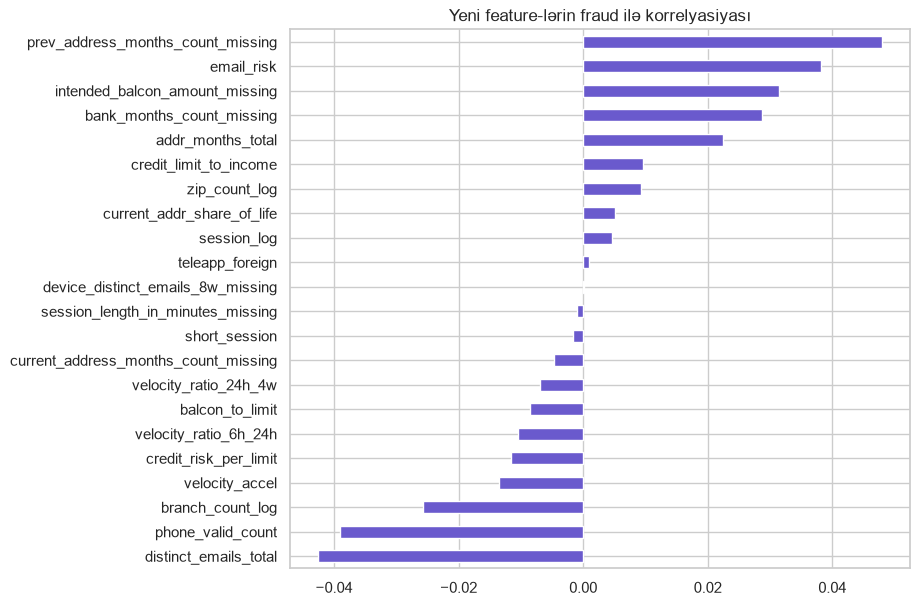

In [41]:
# Yeni feature-lərin target ilə əlaqəsi
corr_new = Xtr_fe[new_feats].corrwith(y_tr).sort_values()
corr_new.plot(kind="barh", figsize=(8, 7), color="slateblue")
plt.title("Yeni feature-lərin fraud ilə korrelyasiyası")
plt.show()

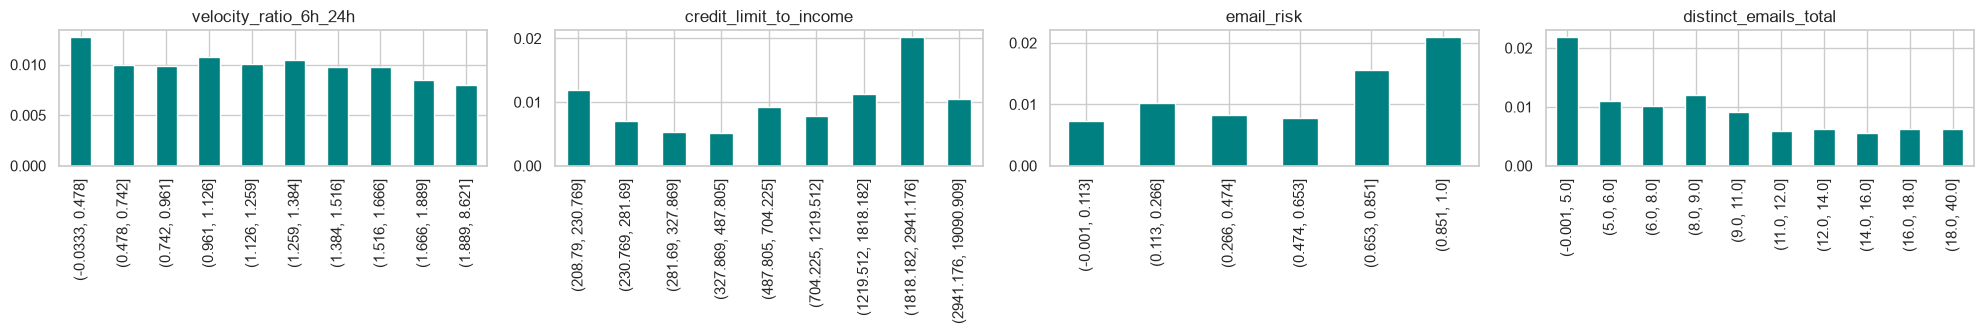

In [42]:
# Seçilmiş feature-lər üzrə fraud faizi (decile)
show = ["velocity_ratio_6h_24h", "credit_limit_to_income", "email_risk", "distinct_emails_total"]
fig, axes = plt.subplots(1, len(show), figsize=(20, 3.5))
for ax, f in zip(axes, show):
    b = pd.qcut(Xtr_fe[f], 10, duplicates="drop")
    y_tr.groupby(b, observed=True).mean().plot(kind="bar", ax=ax, color="teal")
    ax.set_title(f); ax.set_xlabel("")
plt.tight_layout(); plt.show()

## 5. Pipeline
`clean → fe → prep (impute+scale+onehot) → select → model`

In [43]:
pipe_demo = build_pipeline(LogisticRegression(), DROP_COLS)
pipe_demo

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('clean', ...), ('fe', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,drop_cols,"['device_fraud_count', 'month']"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and 

## 6. Model Comparison
**Əsas metrik: PR-AUC.** Fraud ~1% olduğu üçün accuracy yanıltıcıdır, ROC-AUC isə çoxlu true negative ucbatından şişir. Əlavə: TPR@5%FPR (BAF-ın əməliyyat metrikası).

Seçim **valid** üzrədir, test toxunulmaz qalır.

In [44]:
models = {
    # Baseline: sadə, interpretasiya olunan xətti model
    "LogisticRegression": LogisticRegression(C=0.1, class_weight="balanced", max_iter=1000),
    # Bagging: qeyri-xətti, balanced_subsample hər ağac üçün imbalance-i düzəldir
    "RandomForest": RandomForestClassifier(n_estimators=100, min_samples_leaf=30, max_samples=0.2,
                                           class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE),
    # Boosting: tabular datada adətən ən güclü, NaN-ı və böyük datanı sürətlə emal edir
    "HistGradientBoosting": HistGradientBoostingClassifier(learning_rate=0.1, max_depth=6, max_iter=200,
                                                           class_weight="balanced", early_stopping=False,
                                                           random_state=RANDOM_STATE),
}

def evaluate_pipeline(pipe) -> pd.DataFrame:
    """Train/valid/test üçün 3 metrikanı cədvəl kimi qaytarır."""
    return pd.DataFrame({s: score_report(y, pipe.predict_proba(X)[:, 1]) for s, (X, y) in eval_sets.items()}).T

fitted, scores = {}, {}
for name, model in models.items():
    t0 = time.time()
    fitted[name] = build_pipeline(model, DROP_COLS).fit(X_tr, y_tr)
    scores[name] = evaluate_pipeline(fitted[name])
    print(f"{name}: {time.time() - t0:.0f}s")

LogisticRegression: 18s
RandomForest: 31s
HistGradientBoosting: 35s


In [45]:
# Train vs Test fərqi (overfitting yoxlaması)
# Diqqət: fraud nisbəti splitlərdə fərqlidir (train < valid < test), PR-AUC isə baza nisbətindən asılıdır.
# Ona görə splitlər arası müqayisə üçün ROC-AUC-ə də baxırıq.
summary = pd.DataFrame({
    name: {"train_pr_auc": s.loc["train", "pr_auc"], "valid_pr_auc": s.loc["valid", "pr_auc"],
           "test_pr_auc": s.loc["test", "pr_auc"],
           "train_roc_auc": s.loc["train", "roc_auc"], "test_roc_auc": s.loc["test", "roc_auc"],
           "roc_gap_train_minus_test": s.loc["train", "roc_auc"] - s.loc["test", "roc_auc"],
           "valid_tpr@5%fpr": s.loc["valid", "tpr_at_5pct_fpr"]}
    for name, s in scores.items()}).T
print("Fraud nisbəti:", {k: round(v[1].mean(), 4) for k, v in splits.items()})
summary.round(4)

Fraud nisbəti: {'train': np.float64(0.01), 'valid': np.float64(0.0118), 'test': np.float64(0.014)}


,train_pr_auc,valid_pr_auc,test_pr_auc,train_roc_auc,test_roc_auc,roc_gap_train_minus_test,valid_tpr@5%fpr
LogisticRegression,0.1289,0.1615,0.1650,0.8875,0.8828,0.0048,0.5209
RandomForest,0.2031,0.1464,0.1561,0.9583,0.8757,0.0826,0.5103
HistGradientBoosting,0.2111,0.1868,0.1808,0.9503,0.8848,0.0655,0.5308


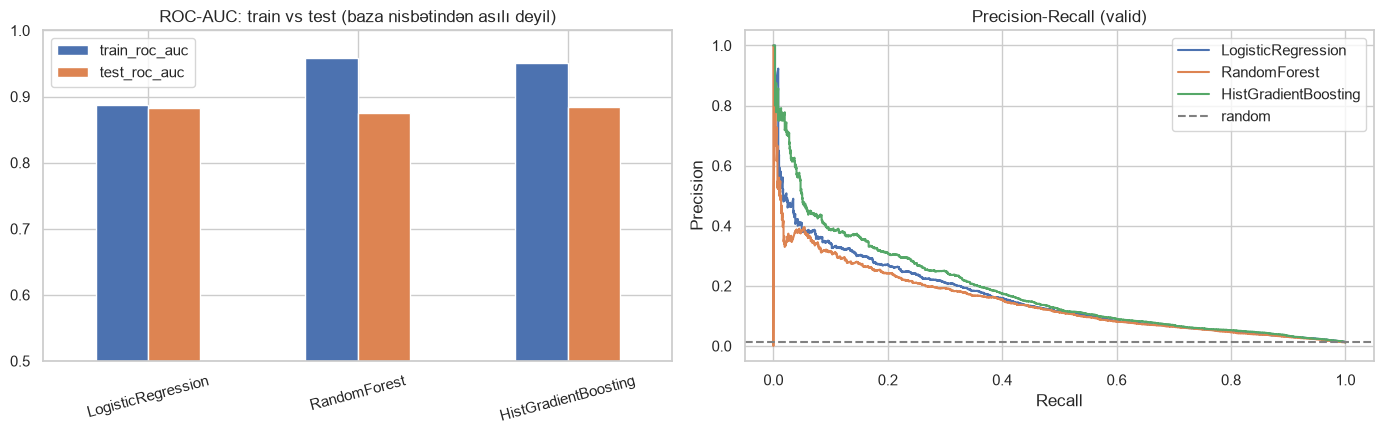

In [46]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
summary[["train_roc_auc", "test_roc_auc"]].plot(kind="bar", ax=ax[0], rot=15, ylim=(0.5, 1))
ax[0].set_title("ROC-AUC: train vs test (baza nisbətindən asılı deyil)")
for name, pipe in fitted.items():
    p, r, _ = precision_recall_curve(y_va, pipe.predict_proba(X_va)[:, 1])
    ax[1].plot(r, p, label=name)
ax[1].axhline(y_va.mean(), ls="--", c="gray", label="random")
ax[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall (valid)"); ax[1].legend()
plt.tight_layout(); plt.show()

In [47]:
best_name = summary["valid_pr_auc"].idxmax()
print("Valid PR-AUC-ə görə ən yaxşı model:", best_name)

Valid PR-AUC-ə görə ən yaxşı model: HistGradientBoosting


## 7. Hyperparameter Tuning
Yalnız ən yaxşı model üçün. Random CV əvəzinə **valid (gələcək ay)** istifadə olunur: təsadüfi CV zaman sızıntısı yaradır.

In [48]:
PARAM_GRIDS = {
    "LogisticRegression": {"model__C": [0.01, 0.1, 1.0]},
    "RandomForest": {"model__min_samples_leaf": [10, 30, 100], "model__max_depth": [10, 16, None]},
    "HistGradientBoosting": {
        "model__learning_rate": [0.03, 0.05, 0.1],   # kiçik lr + çox iter: daha stabil
        "model__max_depth": [3, 5, 8],               # ağac dərinliyi: overfitting nəzarəti
        "model__min_samples_leaf": [20, 100, 300],   # yarpaqda min nümunə: nadir fraud-a həddindən artıq uyğunlaşmanın qarşısı
        "model__l2_regularization": [0.0, 1.0, 10.0],
    },
}
N_ITER = 6
grid = PARAM_GRIDS[best_name]
trials = list(ParameterSampler(grid, n_iter=min(N_ITER, len(ParameterGrid(grid))), random_state=RANDOM_STATE))

rows = []
for params in trials:
    p = clone(fitted[best_name]).set_params(**params).fit(X_tr, y_tr)
    rows.append({**params, "valid_pr_auc": average_precision_score(y_va, p.predict_proba(X_va)[:, 1])})
tuning = pd.DataFrame(rows).sort_values("valid_pr_auc", ascending=False)
tuning.round(4)

,model__min_samples_leaf,model__max_depth,model__learning_rate,model__l2_regularization,valid_pr_auc
4,20,3,0.10,0.0,0.1913
2,100,5,0.10,0.0,0.1851
3,100,5,0.03,1.0,0.1791
0,20,5,0.03,1.0,0.1779
5,100,3,0.03,1.0,0.1659
1,20,3,0.03,0.0,0.1653


In [49]:
base_valid = summary.loc[best_name, "valid_pr_auc"]
best_params = trials[tuning.index[0]]  # ən yaxşı sınağın parametrləri (orijinal tipləri ilə)

if tuning.iloc[0]["valid_pr_auc"] > base_valid:
    tuned = clone(fitted[best_name]).set_params(**best_params).fit(X_tr, y_tr)
    print("Tuning faydalı oldu:", best_params)
else:
    tuned, best_params = fitted[best_name], {}
    print("Tuning baseline-ı keçmədi, baseline saxlanıldı.")
evaluate_pipeline(tuned).round(4)

Tuning faydalı oldu: {'model__min_samples_leaf': 20, 'model__max_depth': 3, 'model__learning_rate': 0.1, 'model__l2_regularization': 0.0}


,pr_auc,roc_auc,tpr_at_5pct_fpr
train,0.1644,0.9123,0.5752
valid,0.1913,0.8972,0.5400
test,0.1938,0.8942,0.5427


## 8. Feature Importance və Best Features ilə Yenidən Model
Permutation importance: feature-i qarışdırıb PR-AUC-in nə qədər düşdüyünü ölçür. Modelə qəsdən bağlı deyil və korrelyasiyalı feature-lərdə impurity-importance-dən etibarlıdır.

In [50]:
# Preprocessing hissəsi (model-dən əvvəl) və model ayrıca
prep_part = Pipeline(tuned.steps[:-1])
est = tuned.named_steps["model"]
va_s = X_va.sample(min(100_000, len(X_va)), random_state=RANDOM_STATE)
Xv_t = prep_part.transform(va_s)

pi = permutation_importance(est, Xv_t, y_va.loc[va_s.index], scoring="average_precision",
                            n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
imp = pd.DataFrame({"mean": pi.importances_mean, "std": pi.importances_std}, index=Xv_t.columns).sort_values("mean", ascending=False)
print("Toplam feature sayı:", len(imp))

Toplam feature sayı: 72


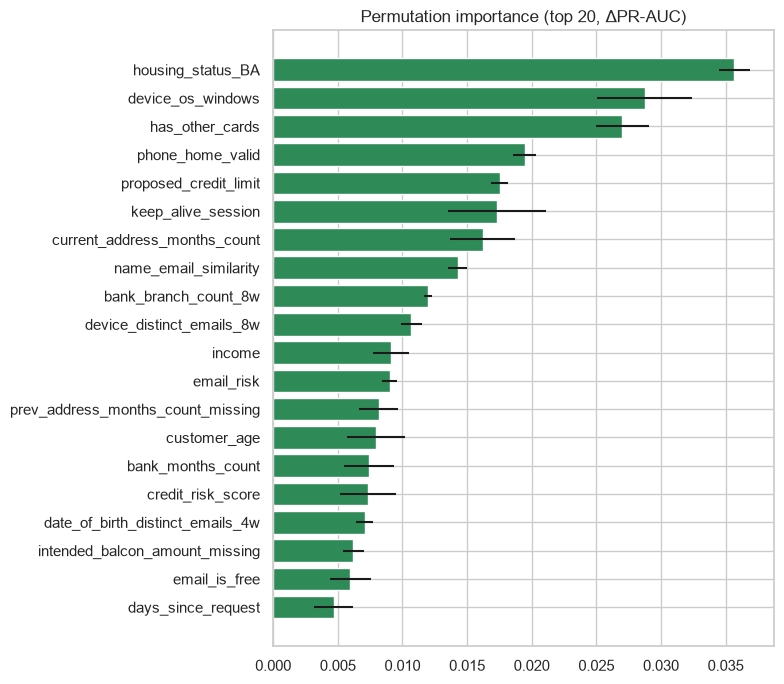

In [51]:
top = imp.head(20)[::-1]
plt.figure(figsize=(8, 7))
plt.barh(top.index, top["mean"], xerr=top["std"], color="seagreen")
plt.title("Permutation importance (top 20, ΔPR-AUC)")
plt.tight_layout(); plt.show()

In [52]:
# Seçim qaydası: müsbət importance-ın kumulyativ 95%-ni əhatə edən ən az feature (minimum 10)
pos = imp[imp["mean"] > 0]["mean"]
cum = pos.cumsum() / pos.sum()
k = max(10, int((cum < 0.95).sum()) + 1)
best_features = list(pos.index[:k])
print(f"{len(imp)} feature-dən {len(best_features)} seçildi")

72 feature-dən 25 seçildi


In [53]:
# Seçilmiş feature-lərlə modeli YENİDƏN qururuq və eyni şəkildə qiymətləndiririk
selected = clone(tuned).set_params(select__keep=best_features).fit(X_tr, y_tr)

comp = pd.DataFrame({
    "all_features": evaluate_pipeline(tuned).stack(),
    "best_features": evaluate_pipeline(selected).stack(),
}).unstack(0)
n_all = len(imp)
print(f"Feature sayı: {n_all} → {len(best_features)}")
comp.round(4)

Feature sayı: 72 → 25


all_features                 best_features                
                       train   valid    test         train   valid    test
pr_auc                0.1644  0.1913  0.1938        0.1581  0.1845  0.1900
roc_auc               0.9123  0.8972  0.8942        0.9055  0.8926  0.8915
tpr_at_5pct_fpr       0.5752  0.5400  0.5427        0.5553  0.5280  0.5462

In [54]:
# Qayda: seçilmiş (az feature) model valid-də statistik olaraq əhəmiyyətli dərəcədə pis DEYİLSƏ, sadə modeli seçirik.
# Fərqin səs-küydən böyük olub-olmadığını paired bootstrap ilə yoxlayırıq (eyni sətirlər, iki model).
def paired_bootstrap_delta(y, p_a, p_b, n_boot=200, seed=RANDOM_STATE):
    """Δ = PR-AUC(b) - PR-AUC(a) üçün orta və 95% inam intervalı (paired bootstrap)."""
    rng = np.random.default_rng(seed)
    y = np.asarray(y)
    deltas = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y), len(y))
        deltas.append(average_precision_score(y[idx], p_b[idx]) - average_precision_score(y[idx], p_a[idx]))
    return float(np.mean(deltas)), np.percentile(deltas, [2.5, 97.5])

pv_all = tuned.predict_proba(X_va)[:, 1]
pv_sel = selected.predict_proba(X_va)[:, 1]
delta, (lo, hi) = paired_bootstrap_delta(y_va, pv_all, pv_sel)
print(f"valid ΔPR-AUC (best - all) = {delta:+.4f}, 95% CI [{lo:+.4f}, {hi:+.4f}]")
significantly_worse = hi < 0
final_pipe = tuned if significantly_worse else selected
final_keep = None if significantly_worse else best_features
print("Nəticə:", "az feature modeli əhəmiyyətli dərəcədə pisdir → hamısı saxlanıldı" if significantly_worse
      else f"fərq əhəmiyyətli deyil → {len(best_features)} feature-li sadə model seçildi")

valid ΔPR-AUC (best - all) = -0.0069, 95% CI [-0.0119, -0.0015]
Nəticə: az feature modeli əhəmiyyətli dərəcədə pisdir → hamısı saxlanıldı


## 9. Calibration
`class_weight='balanced'` ehtimalları şişirir (real fraud faizi ~1%). Bank ehtimala görə qərar verir, ona görə calibration lazımdır.
Valid-in 60%-də iki üsulu (sigmoid, isotonic) fit edirik, 40%-də Brier-ə görə seçirik. Şərt: calibration sıralamanı pozmamalıdır (isotonic bərabər skorlar yaradıb PR-AUC-i endirə bilər). Seçilmişi bütün valid-də yenidən fit edirik.

In [55]:
Xa, Xb, ya, yb = train_test_split(X_va, y_va, test_size=0.4, stratify=y_va, random_state=RANDOM_STATE)
raw_pr = average_precision_score(yb, final_pipe.predict_proba(Xb)[:, 1])   # calibration-dan əvvəl sıralama keyfiyyəti
cal_scores, cal_pr = {}, {}
for method in ["sigmoid", "isotonic"]:
    cal = CalibratedClassifierCV(FrozenEstimator(final_pipe), method=method).fit(Xa, ya)
    p_b = cal.predict_proba(Xb)[:, 1]
    cal_scores[method] = brier_score_loss(yb, p_b)
    cal_pr[method] = average_precision_score(yb, p_b)

# Qayda: Brier ən kiçik olan üsul seçilir, amma yalnız sıralamanı (PR-AUC) pozmayanlar arasından.
# Sigmoid monotondur və sıralamanı saxlayır; isotonic pilləli funksiyadır, bərabər skorlar yarada bilər.
eligible = {m: s for m, s in cal_scores.items() if cal_pr[m] >= raw_pr - 0.001} or {"sigmoid": cal_scores["sigmoid"]}
best_method = min(eligible, key=eligible.get)
print("Brier (valid-B):", {k: round(v, 5) for k, v in cal_scores.items()})
print("PR-AUC (valid-B):", {k: round(v, 4) for k, v in cal_pr.items()}, "| calibration-dan əvvəl:", round(raw_pr, 4))
print("Seçilən:", best_method)

calibrated = CalibratedClassifierCV(FrozenEstimator(final_pipe), method=best_method).fit(X_va, y_va)


Brier (valid-B): {'sigmoid': 0.01042, 'isotonic': 0.01041}
PR-AUC (valid-B): {'sigmoid': 0.1976, 'isotonic': 0.1799} | calibration-dan əvvəl: 0.1976
Seçilən: sigmoid


In [56]:
# Test üzərində: calibration-dan əvvəl və sonra
p_raw = final_pipe.predict_proba(X_te)[:, 1]
p_cal = calibrated.predict_proba(X_te)[:, 1]
cal_table = pd.DataFrame({
    "before": {"brier": brier_score_loss(y_te, p_raw), "log_loss": log_loss(y_te, p_raw),
               "ECE": expected_calibration_error(y_te, p_raw), "pr_auc": average_precision_score(y_te, p_raw)},
    "after": {"brier": brier_score_loss(y_te, p_cal), "log_loss": log_loss(y_te, p_cal),
              "ECE": expected_calibration_error(y_te, p_cal), "pr_auc": average_precision_score(y_te, p_cal)},
}).T
cal_table.round(5)

,brier,log_loss,ECE,pr_auc
before,0.1084,0.35160,0.22889,0.19377
after,0.0124,0.05421,0.00138,0.19377


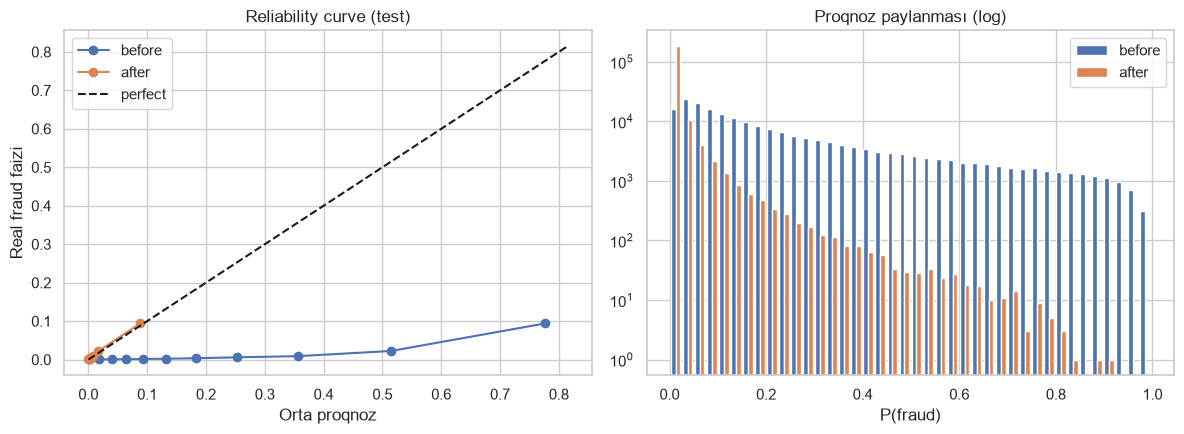

In [57]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for label, p in [("before", p_raw), ("after", p_cal)]:
    frac, mean_p = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    ax[0].plot(mean_p, frac, marker="o", label=label)
m = max(ax[0].get_xlim()[1], ax[0].get_ylim()[1])
ax[0].plot([0, m], [0, m], "k--", label="perfect")
ax[0].set(xlabel="Orta proqnoz", ylabel="Real fraud faizi", title="Reliability curve (test)"); ax[0].legend()
ax[1].hist([p_raw, p_cal], bins=40, log=True, label=["before", "after"])
ax[1].set(title="Proqnoz paylanması (log)", xlabel="P(fraud)"); ax[1].legend()
plt.tight_layout(); plt.show()

## 10. Threshold Optimization
Biznes xərci: buraxılmış fraud (FN) yanlış alarmdan (FP) çox bahadır. Fərziyyələr `src/config.py`-dadır, aşağıda həssaslıq analizi var.
Calibrated ehtimal üçün nəzəri optimum: `t* = C_FP / (C_FP + C_FN)`. Empirik axtarışla yoxlayırıq.

In [58]:
p_va = calibrated.predict_proba(X_va)[:, 1]
tt = threshold_table(y_va, p_va, COST_FN, COST_FP)
best_row = tt.loc[tt["cost_per_1000"].idxmin()]
THRESHOLD = float(best_row["threshold"])
print(f"Empirik optimal threshold (valid): {THRESHOLD:.4f}")
print(f"Nəzəri t* = C_FP/(C_FP+C_FN): {COST_FP / (COST_FP + COST_FN):.4f}")

Empirik optimal threshold (valid): 0.0131
Nəzəri t* = C_FP/(C_FP+C_FN): 0.0196


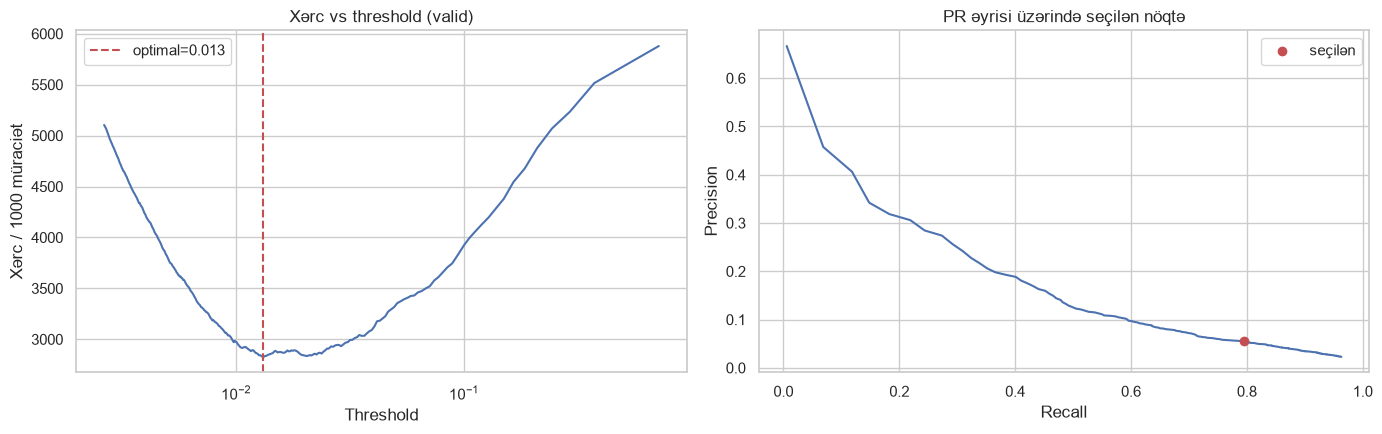

In [59]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(tt["threshold"], tt["cost_per_1000"])
ax[0].axvline(THRESHOLD, c="r", ls="--", label=f"optimal={THRESHOLD:.3f}")
ax[0].set(xscale="log", xlabel="Threshold", ylabel="Xərc / 1000 müraciət", title="Xərc vs threshold (valid)"); ax[0].legend()
ax[1].plot(tt["recall"], tt["precision"])
ax[1].scatter(best_row["recall"], best_row["precision"], c="r", zorder=3, label="seçilən")
ax[1].set(xlabel="Recall", ylabel="Precision", title="PR əyrisi üzərində seçilən nöqtə"); ax[1].legend()
plt.tight_layout(); plt.show()

In [60]:
# Strategiyaların test üzərində müqayisəsi (threshold-lar valid-dən götürülür)
p_te = calibrated.predict_proba(X_te)[:, 1]
strategies = {
    "default 0.5": 0.5,
    "F1-optimal": float(tt.loc[tt["f1"].idxmax(), "threshold"]),
    "FPR<=5%": threshold_at_fpr(y_va, p_va, 0.05),
    "cost-optimal (seçilən)": THRESHOLD,
}
cmp = pd.DataFrame({k: operating_point(y_te, p_te, t, COST_FN, COST_FP) for k, t in strategies.items()}).T
n_te = len(y_te)
ref = pd.DataFrame({"cost_per_1000": {"heç kəsi bloklama": COST_FN * y_te.sum() / n_te * 1000,
                                       "hamını blokla": COST_FP * (n_te - y_te.sum()) / n_te * 1000}})
display_cols = ["threshold", "precision", "recall", "fpr", "flag_rate", "cost_per_1000"]
print("Referans (xərc/1000):", ref["cost_per_1000"].round(0).to_dict())
cmp[display_cols].round(4)

Referans (xərc/1000): {'heç kəsi bloklama': 7019.0, 'hamını blokla': 9860.0}


,threshold,precision,recall,fpr,flag_rate,cost_per_1000
default 0.5,0.5000,0.5743,0.0403,0.0004,0.0010,6740.4188
F1-optimal,0.1498,0.2589,0.2564,0.0105,0.0139,5322.2998
FPR<=5%,0.0449,0.1285,0.5587,0.0540,0.0611,3629.5613
cost-optimal (seçilən),0.0131,0.0628,0.8016,0.1704,0.1793,3073.1522


In [61]:
# Həssaslıq: FN/FP xərc nisbəti dəyişəndə optimal threshold necə dəyişir (valid-də axtarış)
sens = []
for ratio in [10, 25, 50, 100, 250]:
    t_ = threshold_table(y_va, p_va, COST_FP * ratio, COST_FP)
    r_ = t_.loc[t_["cost_per_1000"].idxmin()]
    sens.append({"FN/FP nisbəti": ratio, "threshold": r_["threshold"], "recall": r_["recall"], "precision": r_["precision"], "flag_rate": r_["flag_rate"]})
pd.DataFrame(sens).round(4)

,FN/FP nisbəti,threshold,recall,precision,flag_rate
0,10,0.0889,0.4011,0.1884,0.0252
1,25,0.0366,0.5911,0.1018,0.0687
2,50,0.0131,0.7945,0.0551,0.1706
3,100,0.0098,0.8427,0.0465,0.2141
4,250,0.0051,0.9206,0.0321,0.3395


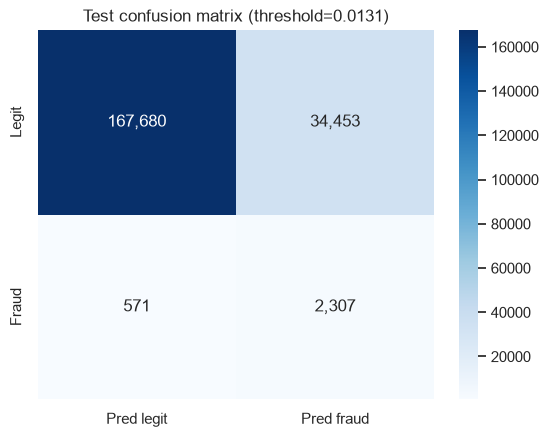

In [62]:
# Seçilən threshold-da test confusion matrix
op = operating_point(y_te, p_te, THRESHOLD, COST_FN, COST_FP)
cm = np.array([[op["tn"], op["fp"]], [op["fn"], op["tp"]]])
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", xticklabels=["Pred legit", "Pred fraud"], yticklabels=["Legit", "Fraud"])
plt.title(f"Test confusion matrix (threshold={THRESHOLD:.4f})"); plt.show()

## 11. Fairness yoxlaması (yaş)
BAF həssas atribut kimi `customer_age`-i qeyd edir. Seçilən threshold-da qruplar üzrə recall və FPR-ə baxırıq.

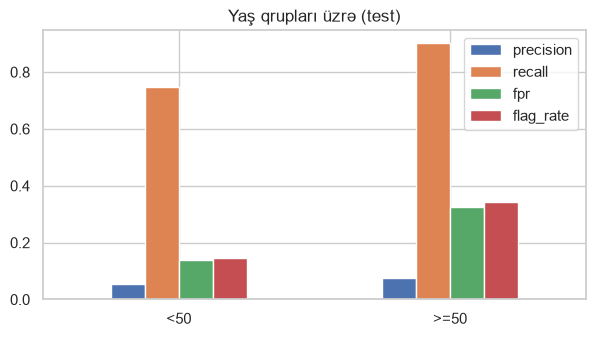

,precision,recall,fpr,flag_rate
<50,0.0561,0.7485,0.1404,0.1471
>=50,0.0772,0.9029,0.3255,0.3424


In [63]:
older = (X_te["customer_age"] >= 50).values
rows = {}
for name, mask in [("<50", ~older), (">=50", older)]:
    o = operating_point(y_te[mask], p_te[mask], THRESHOLD, COST_FN, COST_FP)
    rows[name] = {k: o[k] for k in ["precision", "recall", "fpr", "flag_rate"]}
fair = pd.DataFrame(rows).T
fair.plot(kind="bar", rot=0, figsize=(7, 3.5), title="Yaş qrupları üzrə (test)")
plt.show()
fair.round(4)

In [64]:
# Variant: hər qrupda FPR≈5% verən ayrıca threshold (valid-də seçilir, test-də ölçülür)
older_va = (X_va["customer_age"] >= 50).values
rows = {}
for name, m_va, m_te in [("<50", ~older_va, ~older), (">=50", older_va, older)]:
    t_g = threshold_at_fpr(y_va[m_va], p_va[m_va], 0.05)
    o = operating_point(y_te[m_te], p_te[m_te], t_g, COST_FN, COST_FP)
    rows[name] = {"threshold": t_g, **{k: o[k] for k in ["recall", "fpr", "flag_rate", "precision"]}}
pd.DataFrame(rows).T.round(4)

,threshold,recall,fpr,flag_rate,precision
<50,0.0347,0.5384,0.0526,0.0580,0.1024
>=50,0.0980,0.5207,0.0577,0.0712,0.2140


Qrup üzrə threshold FPR fərqini azaldır, amma qərarda həssas atributdan istifadə deməkdir (hüquqi və etik məsələ). Bu ilkin analizdir, tövsiyə deyil.

## 12. Final Evaluation və Artefaktlar
Test yalnız indi final rəqəm üçün istifadə olunur.

In [65]:
final_scores = {"raw_model": score_report(y_te, p_raw), "calibrated": score_report(y_te, p_cal)}
pd.DataFrame(final_scores).T.round(4)

,pr_auc,roc_auc,tpr_at_5pct_fpr
raw_model,0.1938,0.8942,0.5427
calibrated,0.1938,0.8942,0.5427


In [67]:
# Streamlit üçün giriş sxemi: hər xam feature üçün tip, aralıq, default
input_cols = [c for c in X_tr.columns if c not in DROP_COLS]
schema = {}
for col in input_cols:
    if col in CATEGORICAL:
        schema[col] = {"type": "cat", "choices": sorted(X_tr[col].unique().tolist()), "default": X_tr[col].mode()[0]}
    else:
        is_int = bool((X_tr[col].dropna() % 1 == 0).all())
        schema[col] = {"type": "int" if is_int else "float", "min": float(X_tr[col].min()), "max": float(X_tr[col].max()),
                       "default": float(X_tr[col].median())}

# Demo nümunələri: test-dən real sətirlər (ən yüksək skorlu fraud və aşağı skorlu legit)
fraud_idx = y_te[y_te == 1].index
top_fraud = pd.Series(p_te, index=X_te.index).loc[fraud_idx].idxmax()
legit_idx = pd.Series(p_te, index=X_te.index)[y_te == 0].idxmin()
examples = {"Adi müştəri (aşağı risk)": X_te.loc[legit_idx, input_cols].to_dict(),
            "Şübhəli müraciət (fraud nümunəsi)": X_te.loc[top_fraud, input_cols].to_dict()}

def to_py(o):
    """numpy tiplərini JSON üçün Python tiplərinə çevirir."""
    return o.item() if hasattr(o, "item") else o

meta = {
    "model": best_name, "params": {k: to_py(v) for k, v in best_params.items()},
    "n_features_used": len(final_keep) if final_keep else len(imp), "features_used": final_keep,
    "calibration": best_method, "threshold": THRESHOLD,
    "cost_fn": COST_FN, "cost_fp": COST_FP,
    "test_metrics": {k: {m: float(v) for m, v in s.items()} for k, s in final_scores.items()},
    "operating_point_test": {k: to_py(v) for k, v in op.items()},
    "input_schema": schema,
    "examples": {k: {c: to_py(v) for c, v in row.items()} for k, row in examples.items()},
}
joblib.dump(calibrated, "models/model.joblib", compress=3)
Path("models/meta.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")
print("Model ölçüsü: %.1f MB" % (Path("models/model.joblib").stat().st_size / 1e6))

Model ölçüsü: 0.1 MB


In [ ]:
# Yoxlama: saxlanmış modeli yenidən yükləyib eyni nəticə verdiyini təsdiqləyirik
reloaded = joblib.load("models/model.joblib")
assert np.allclose(reloaded.predict_proba(X_te.head(1000))[:, 1], p_te[:1000])
print("Reload OK")

Reload OK


In [ ]:
# README-nin nəticə bölməsini avtomatik yeniləyirik (rəqəmlər əl ilə yazılmır)
m, o = meta["test_metrics"]["calibrated"], meta["operating_point_test"]
def fmt(x):
    """Rəqəmi 3 onluq işarə ilə formatlayır."""
    return f"{x:.3f}"
block = f"""<!-- RESULTS_START -->
| Göstərici | Dəyər |
|---|---|
| Seçilən model | {best_name} ({meta['n_features_used']} feature) |
| Test PR-AUC | {fmt(m['pr_auc'])} |
| Test ROC-AUC | {fmt(m['roc_auc'])} |
| Test TPR @ 5% FPR | {fmt(m['tpr_at_5pct_fpr'])} |
| Calibration | {best_method} (test ECE {cal_table.loc['after','ECE']:.4f}, əvvəl {cal_table.loc['before','ECE']:.4f}) |
| Threshold (xərcə görə) | {THRESHOLD:.4f} |
| Threshold-da recall / precision | {fmt(o['recall'])} / {fmt(o['precision'])} |
| Alarm nisbəti | {o['flag_rate']:.2%} |
<!-- RESULTS_END -->"""
readme = Path("README.md").read_text()
Path("README.md").write_text(re.sub(r"<!-- RESULTS_START -->.*?<!-- RESULTS_END -->", lambda _: block, readme, flags=re.S))
print(block)

<!-- RESULTS_START -->
| Göstərici | Dəyər |
|---|---|
| Seçilən model | HistGradientBoosting (72 feature) |
| Test PR-AUC | 0.193 |
| Test ROC-AUC | 0.894 |
| Test TPR @ 5% FPR | 0.542 |
| Calibration | sigmoid (test ECE 0.0016, əvvəl 0.2263) |
| Threshold (xərcə görə) | 0.0130 |
| Threshold-da recall / precision | 0.801 / 0.063 |
| Alarm nisbəti | 17.72% |
<!-- RESULTS_END -->


## 13. Nəticə
Bütün rəqəmlər yuxarıdakı cədvəllərdə və `README.md`-nin nəticə bölməsindədir.